# Deep Hedging with Market Frictions — Phase I
**AMS 520: Machine Learning in Quantitative Finance (Fall 2026)**

**Phase I scope (per syllabus):** literature survey, data collection, and data cleaning.

## Project in one paragraph
A bank that sells an option must hedge it by trading the underlying asset. The classical Black–Scholes
delta hedge assumes continuous, free trading and a known model. In reality trading is discrete, costly,
and the model is wrong. **Deep hedging** (Buehler et al., 2019) instead trains a neural-network trading
policy on many simulated market scenarios to minimize a tail-risk measure (CVaR) of the hedging P&L.

## Why real data is needed
1. **Calibration** — estimate volatility, rates and model parameters so the simulator is realistic.
2. **Out-of-model testing** — evaluate the trained hedger on *real historical* price paths that the simulator never produced.

## Data used in this notebook (all free, no credentials)
| Series | Source | Role |
|---|---|---|
| SPY (S&P 500 ETF), daily, adjusted | Yahoo Finance via `yfinance` | Underlying asset to hedge |
| VIX index, daily | Yahoo Finance (`^VIX`) | Market-implied volatility |
| 3-month T-bill rate (`DTB3`) | FRED (St. Louis Fed) | Risk-free rate |

## 1. Setup

In [1]:
# In Google Colab, yfinance may need installing. Safe to run everywhere.
%pip install -q yfinance

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import yfinance as yf

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 2. Configuration
All choices in one place so results are reproducible.

In [2]:
START = "2005-01-01"      # covers 2008 crisis, 2020 COVID crash, 2022 rate hikes
END   = "2026-09-30"
TICKER, VIX_TICKER, RATE_SERIES = "SPY", "^VIX", "DTB3"

HORIZON = 21              # trading days ≈ 1 calendar month: maturity of the option we hedge
TRADING_DAYS = 252
TRAIN_END = "2018-12-31"  # train/calibrate on data up to here, test on data after (no look-ahead)
OUTLIER_Z = 5.0           # robust z-score threshold to FLAG extreme returns
MAX_RATE_FFILL = 5        # max consecutive days a missing rate may be forward-filled

## 3. Data collection
Raw downloads are saved untouched in `data/raw/` so cleaning can always be re-run from the originals.

In [3]:
def download_yahoo(ticker):
    df = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)
    if isinstance(df.columns, pd.MultiIndex):        # newer yfinance returns (field, ticker) columns
        df.columns = df.columns.get_level_values(0)
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "date"
    return df

def download_fred(series):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
    df = pd.read_csv(url, na_values=".")
    df.columns = ["date", series]
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date").loc[START:END]
    return df

spy_raw  = download_yahoo(TICKER)
vix_raw  = download_yahoo(VIX_TICKER)
rate_raw = download_fred(RATE_SERIES)

spy_raw.to_csv("data/raw/spy_raw.csv")
vix_raw.to_csv("data/raw/vix_raw.csv")
rate_raw.to_csv("data/raw/dtb3_raw.csv")
print("SPY:", spy_raw.shape, "| VIX:", vix_raw.shape, "| DTB3:", rate_raw.shape)
spy_raw.tail()

SPY: (5469, 5) | VIX: (5471, 5) | DTB3: (5673, 1)


Price,Close,High,Low,Open,Volume
date,,,,,
2026-09-23,767.8100,773.0500,766.5000,772.7900,54931700
2026-09-24,767.1800,768.9500,763.2500,764.0700,43983700
2026-09-25,771.3500,772.2800,766.2900,768.7800,36666700
2026-09-28,765.6100,769.5400,763.7200,768.3500,42694500
2026-09-29,764.2000,766.9800,762.3500,766.8300,36910500


## 4. Raw data audit
Before cleaning, document what is wrong with the raw data.

In [4]:
def audit(name, df, col):
    s = df[col]
    return {
        "dataset": name, "rows": len(df),
        "first date": df.index.min().date(), "last date": df.index.max().date(),
        "missing values": int(s.isna().sum()),
        "duplicate dates": int(df.index.duplicated().sum()),
        "non-positive values": int((s <= 0).sum()),
    }

audit_raw = pd.DataFrame([
    audit("SPY (Close)", spy_raw, "Close"),
    audit("VIX (Close)", vix_raw, "Close"),
    audit("DTB3 (rate %)", rate_raw, RATE_SERIES),
]).set_index("dataset")
audit_raw

,rows,first date,last date,missing values,duplicate dates,non-positive values
dataset,,,,,,
SPY (Close),5469,2005-01-03,2026-09-29,0,0,0
VIX (Close),5471,2005-01-03,2026-09-29,0,0,0
DTB3 (rate %),5673,2005-01-03,2026-09-30,232,0,21


## 5. Data cleaning
Every step is logged so the cleaning can be reported (row counts before/after and the reason).

| Step | What | Why |
|---|---|---|
| 1 | Adjusted prices (`auto_adjust=True`) | Splits/dividends would create fake jumps |
| 2 | Drop duplicates, missing and non-positive prices | Invalid observations |
| 3 | VIX from % points to decimal | VIX 20 = 20% annual volatility |
| 4 | T-bill: % → decimal, discount basis → continuously compounded | Pricing models use continuous rates |
| 5 | Align everything on the SPY trading calendar | Bond and stock market holidays differ |
| 6 | Forward-fill rate gaps ≤ 5 days only | Rates barely move over a holiday; long gaps are suspicious |
| 7 | Log returns and realized volatility | Inputs for calibration and analysis |
| 8 | **Flag** (do not delete) extreme returns | Crashes are real and matter most for hedging risk |

In [5]:
log = []
def record(step, before, after, note):
    log.append({"step": step, "rows before": before, "rows after": after,
                "removed": before - after, "note": note})

# --- SPY ---
spy = spy_raw[["Close", "Volume"]].rename(columns={"Close": "spy", "Volume": "volume"}).copy()
n = len(spy); spy = spy[~spy.index.duplicated(keep="first")].sort_index()
record("SPY: drop duplicate dates", n, len(spy), "keep first")
n = len(spy); spy = spy.dropna(subset=["spy"]); spy = spy[spy["spy"] > 0]
record("SPY: drop missing / non-positive prices", n, len(spy), "invalid quotes")
n = len(spy); spy = spy[spy["volume"] > 0]
record("SPY: drop zero-volume days", n, len(spy), "no trading = stale price")

# --- VIX ---
vix = vix_raw[["Close"]].rename(columns={"Close": "vix"}).copy()
n = len(vix); vix = vix[~vix.index.duplicated(keep="first")].dropna()
vix = vix[vix["vix"] > 0]
record("VIX: drop duplicates / missing / non-positive", n, len(vix), "invalid quotes")
vix["vix"] = vix["vix"] / 100.0

# --- Risk-free rate ---
rate = rate_raw.rename(columns={RATE_SERIES: "tbill_discount"}).copy()
rate["tbill_discount"] = rate["tbill_discount"] / 100.0
# Discount yield -> bond-equivalent price -> continuously compounded rate (91-day bill)
d, T = rate["tbill_discount"], 91 / 360
price = 1 - d * T
rate["r"] = -np.log(price) / (91 / 365)

# --- Align on SPY calendar ---
n = len(spy)
df = spy.join(vix, how="inner")
record("Align SPY with VIX (inner join)", n, len(df), "dates present in both")
df = df.join(rate[["r"]], how="left")
missing_r_before = int(df["r"].isna().sum())
df["r"] = df["r"].ffill(limit=MAX_RATE_FFILL)
n = len(df); df = df.dropna(subset=["r"])
record("Rate: forward-fill <= 5 days, drop rest", n, len(df),
       f"{missing_r_before} missing rates before filling")

# --- Features ---
df["log_ret"] = np.log(df["spy"]).diff()
df["realized_vol_21d"] = df["log_ret"].rolling(HORIZON).std() * np.sqrt(TRADING_DAYS)
n = len(df); df = df.dropna(subset=["log_ret"])
record("Drop first row (no return)", n, len(df), "return needs a previous price")

# --- Flag extreme returns with a robust (median/MAD) z-score ---
med = df["log_ret"].median()
mad = stats.median_abs_deviation(df["log_ret"], scale="normal")
df["robust_z"] = (df["log_ret"] - med) / mad
df["extreme_flag"] = df["robust_z"].abs() > OUTLIER_Z

cleaning_log = pd.DataFrame(log)
cleaning_log

,step,rows before,rows after,removed,note
0,SPY: drop duplicate dates,5469,5469,0,keep first
1,SPY: drop missing / non-positive prices,5469,5469,0,invalid quotes
2,SPY: drop zero-volume days,5469,5469,0,no trading = stale price
3,VIX: drop duplicates / missing / non-positive,5471,5471,0,invalid quotes
4,Align SPY with VIX (inner join),5469,5469,0,dates present in both
5,"Rate: forward-fill <= 5 days, drop rest",5469,5469,0,39 missing rates before filling
6,Drop first row (no return),5469,5468,1,return needs a previous price


### Quality checks
These assertions fail loudly if anything is wrong with the cleaned data.

In [6]:
assert df.index.is_monotonic_increasing and not df.index.duplicated().any()
assert (df["spy"] > 0).all() and (df["vix"] > 0).all()
assert df[["spy", "vix", "r", "log_ret"]].notna().all().all()
assert df["vix"].between(0.05, 1.0).all(), "VIX outside 5%-100%: check units"
assert df["r"].between(-0.01, 0.10).all(), "Rate outside -1%..10%: check units"
gaps = df.index.to_series().diff().dt.days
print("All checks passed.")
print(f"Clean sample: {df.index.min().date()} to {df.index.max().date()}, {len(df):,} trading days")
print(f"Largest calendar gap between observations: {gaps.max():.0f} days (on {gaps.idxmax().date()})")

All checks passed.
Clean sample: 2005-01-04 to 2026-09-29, 5,468 trading days
Largest calendar gap between observations: 5 days (on 2007-01-03)


### Extreme days (flagged, kept)
These line up with known market events, which confirms they are real and not data errors.

In [7]:
extreme = df.loc[df["extreme_flag"], ["spy", "log_ret", "robust_z", "vix"]]
print(f"{len(extreme)} of {len(df)} days flagged ({len(extreme)/len(df):.2%})")
extreme.reindex(extreme["log_ret"].abs().sort_values(ascending=False).index).head(10)

89 of 5468 days flagged (1.63%)


,spy,log_ret,robust_z,vix
date,,,,
2008-10-13,73.1495,0.1356,18.5763,0.5499
2020-03-16,218.0864,-0.1159,-16.0588,0.8269
2008-10-28,67.6714,0.1105,15.1247,0.6696
2008-10-15,64.9720,-0.1036,-14.3716,0.6925
2020-03-12,225.5969,-0.1006,-13.9489,0.7547
2025-04-09,539.6683,0.0999,13.6573,0.3362
2008-12-01,59.2630,-0.0927,-12.8720,0.6851
2020-03-24,222.3870,0.0867,11.8486,0.6167
2020-03-13,244.8823,0.0820,11.2008,0.5783


## 6. Summary statistics of the cleaned data

In [8]:
r = df["log_ret"]
summary = pd.Series({
    "Annualized mean return": r.mean() * TRADING_DAYS,
    "Annualized volatility": r.std() * np.sqrt(TRADING_DAYS),
    "Skewness": stats.skew(r),
    "Excess kurtosis": stats.kurtosis(r),          # 0 for a normal distribution
    "Min daily return": r.min(),
    "Max daily return": r.max(),
    "Jarque-Bera p-value": stats.jarque_bera(r).pvalue,
    "Mean VIX": df["vix"].mean(),
    "Mean risk-free rate": df["r"].mean(),
}, name="value")
summary.to_frame()

,value
Annualized mean return,0.1035
Annualized volatility,0.1890
Skewness,-0.3034
Excess kurtosis,14.7498
Min daily return,-0.1159
Max daily return,0.1356
Jarque-Bera p-value,0.0000
Mean VIX,0.1912
Mean risk-free rate,0.0181


**Reading this table:** large excess kurtosis and a Jarque–Bera p-value near zero mean daily returns are
**not normally distributed** (fat tails). Black–Scholes assumes normal log-returns, so this is the first piece
of evidence that model-based hedging is fragile, and the motivation for the project. Full EDA follows in Phase II.

## 7. Plots of the cleaned data

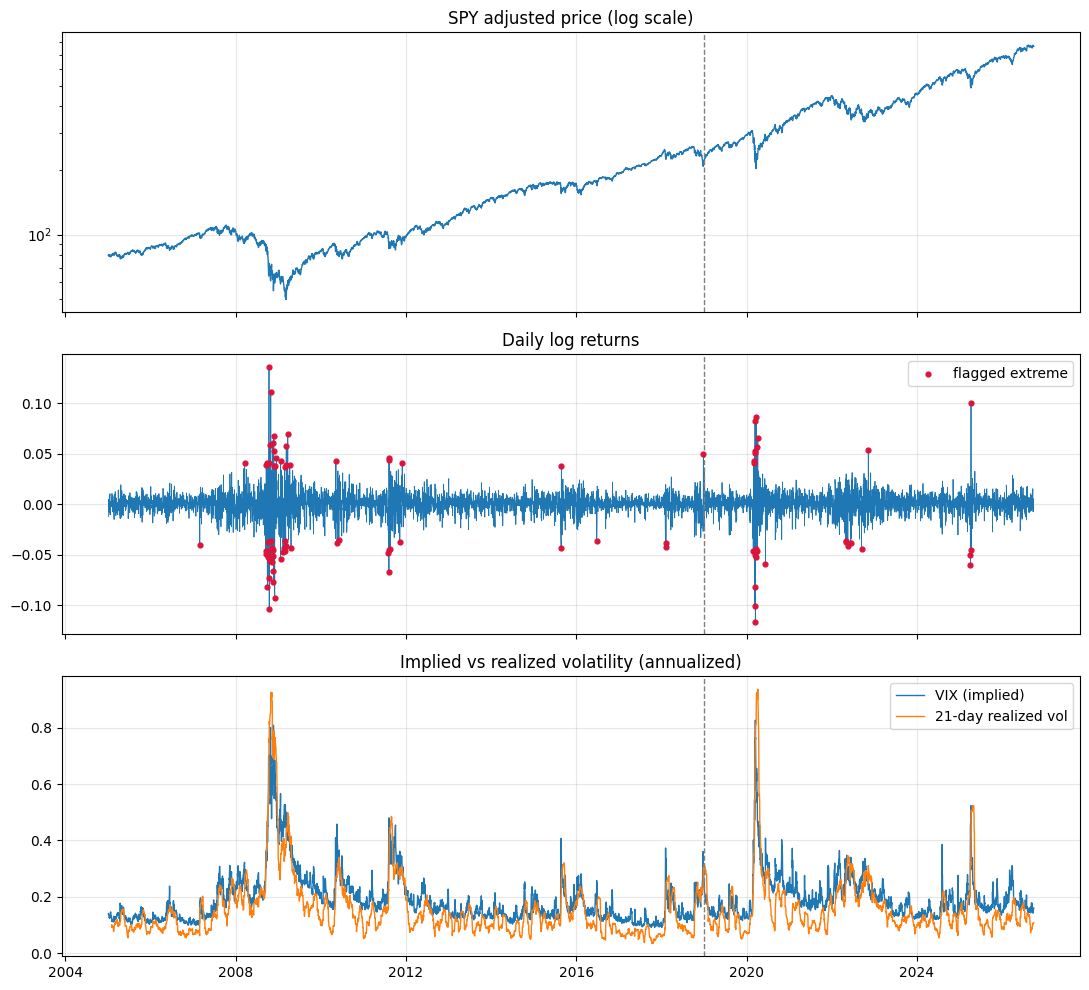

In [9]:
fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
ax[0].plot(df.index, df["spy"], lw=1); ax[0].set_yscale("log")
ax[0].set_title("SPY adjusted price (log scale)")
ax[1].plot(df.index, df["log_ret"], lw=0.6)
ax[1].scatter(extreme.index, extreme["log_ret"], s=12, color="crimson", label="flagged extreme", zorder=3)
ax[1].set_title("Daily log returns"); ax[1].legend()
ax[2].plot(df.index, df["vix"], lw=1, label="VIX (implied)")
ax[2].plot(df.index, df["realized_vol_21d"], lw=1, label="21-day realized vol")
ax[2].set_title("Implied vs realized volatility (annualized)"); ax[2].legend()
for a in ax: a.axvline(pd.Timestamp(TRAIN_END), color="gray", ls="--", lw=1)
plt.tight_layout(); plt.savefig("figures/01_clean_series.png", dpi=150); plt.show()

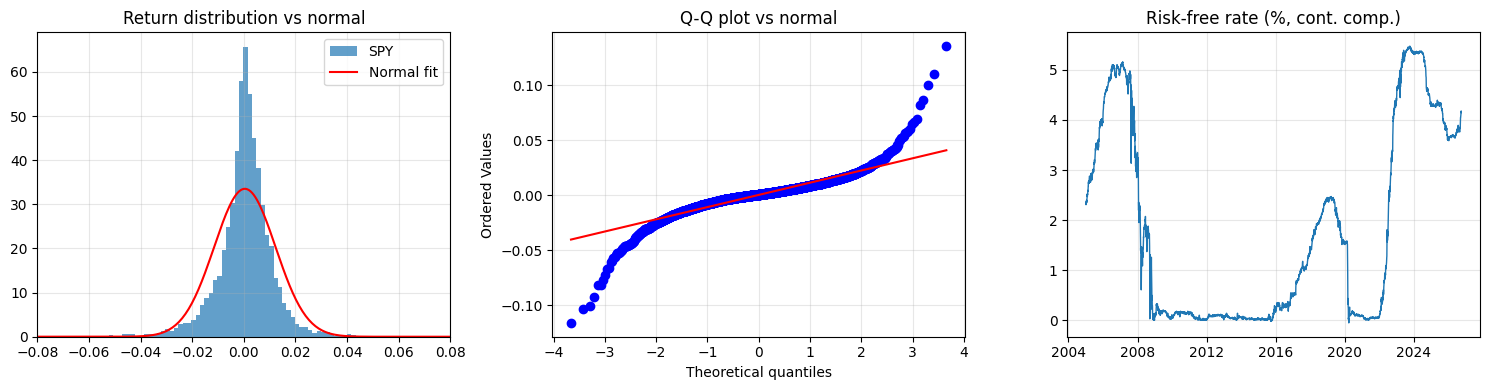

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(r, bins=150, density=True, alpha=0.7, label="SPY")
x = np.linspace(r.min(), r.max(), 400)
ax[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r", label="Normal fit")
ax[0].set_xlim(-0.08, 0.08); ax[0].set_title("Return distribution vs normal"); ax[0].legend()
stats.probplot(r, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot vs normal")
ax[2].plot(df.index, df["r"] * 100, lw=1); ax[2].set_title("Risk-free rate (%, cont. comp.)")
plt.tight_layout(); plt.savefig("figures/02_distribution_and_rates.png", dpi=150); plt.show()

## 8. Building real hedging paths
The hedger will later be **tested on real history**. Each test case is one option's life: a window of
`HORIZON + 1` consecutive prices (21 trading days ≈ a 1-month option), rescaled to start at 100 so all
windows are comparable.

* **Non-overlapping windows** are independent test cases.
* **Train / test split by date:** windows ending on or before `TRAIN_END` may be used for calibration;
  windows after it are kept for final testing only. This prevents look-ahead bias.

In [11]:
def make_windows(prices, horizon, step):
    vals, idx = prices.values, prices.index
    paths, starts, ends = [], [], []
    for i in range(0, len(vals) - horizon, step):
        w = vals[i:i + horizon + 1]
        paths.append(100.0 * w / w[0]); starts.append(idx[i]); ends.append(idx[i + horizon])
    return np.array(paths), pd.DatetimeIndex(starts), pd.DatetimeIndex(ends)

paths, starts, ends = make_windows(df["spy"], HORIZON, step=HORIZON)
is_train = ends <= pd.Timestamp(TRAIN_END)
is_test = starts > pd.Timestamp(TRAIN_END)          # windows straddling the split are dropped

meta = pd.DataFrame({
    "start": starts, "end": ends,
    "vix_at_start": df["vix"].reindex(starts).values,
    "r_at_start": df["r"].reindex(starts).values,
    "split": np.where(is_train, "train", np.where(is_test, "test", "dropped")),
})
print(meta["split"].value_counts())
print("Path array shape (windows, days+1):", paths.shape)

split
train      167
test        92
dropped      1
Name: count, dtype: int64
Path array shape (windows, days+1): (260, 22)


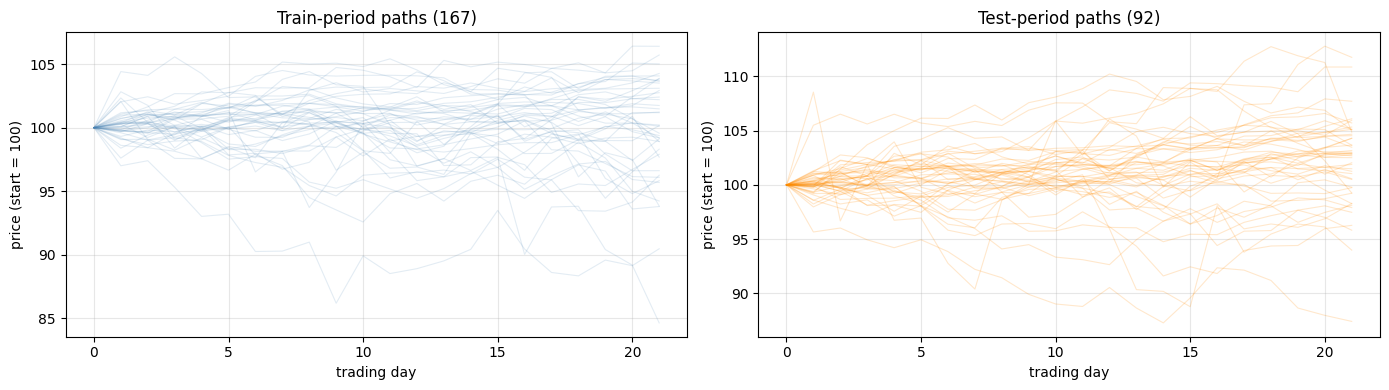

1-month return of windows: mean 0.99%, std 4.80%, worst -25.99%


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for p in paths[is_train][::4]: ax[0].plot(p, color="steelblue", alpha=0.15, lw=0.8)
for p in paths[is_test][::2]:  ax[1].plot(p, color="darkorange", alpha=0.2, lw=0.8)
ax[0].set_title(f"Train-period paths ({is_train.sum()})"); ax[1].set_title(f"Test-period paths ({is_test.sum()})")
for a in ax: a.set_xlabel("trading day"); a.set_ylabel("price (start = 100)")
plt.tight_layout(); plt.savefig("figures/03_hedging_paths.png", dpi=150); plt.show()

term = paths[:, -1] / 100 - 1
print(f"1-month return of windows: mean {term.mean():.2%}, std {term.std():.2%}, worst {term.min():.2%}")

## 9. Save processed data
These files are the input to Phase II (EDA, calibration, first hedging results).

In [13]:
df.to_csv("data/processed/market_daily_clean.csv")
meta.to_csv("data/processed/hedging_windows_meta.csv", index=False)
np.save("data/processed/hedging_paths.npy", paths)
cleaning_log.to_csv("data/processed/cleaning_log.csv", index=False)
summary.to_csv("data/processed/summary_stats.csv")
print(sorted(os.listdir("data/processed")))

['cleaning_log.csv', 'hedging_paths.npy', 'hedging_windows_meta.csv', 'market_daily_clean.csv', 'summary_stats.csv']


In [14]:
   !zip -r phase1_outputs.zip data figures
   from google.colab import files; files.download("phase1_outputs.zip")

  adding: data/ (stored 0%)
  adding: data/raw/ (stored 0%)
  adding: data/raw/spy_raw.csv (deflated 57%)
  adding: data/raw/vix_raw.csv (deflated 84%)
  adding: data/raw/dtb3_raw.csv (deflated 80%)
  adding: data/processed/ (stored 0%)
  adding: data/processed/hedging_windows_meta.csv (deflated 72%)
  adding: data/processed/summary_stats.csv (deflated 30%)
  adding: data/processed/market_daily_clean.csv (deflated 64%)
  adding: data/processed/cleaning_log.csv (deflated 46%)
  adding: data/processed/hedging_paths.npy (deflated 13%)
  adding: figures/ (stored 0%)
  adding: figures/01_clean_series.png (deflated 5%)
  adding: figures/02_distribution_and_rates.png (deflated 8%)
  adding: figures/03_hedging_paths.png (deflated 2%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Next steps
**Phase II — EDA and first empirical results**
* Stylized facts: fat tails, volatility clustering (ACF of squared returns), leverage effect.
* Calibrate GBM and Heston to the training period.
* Build the deep hedging pipeline: path simulator → policy network → P&L → CVaR loss.
* Sanity check: without costs the network should recover the Black–Scholes delta.
* With transaction costs: compare P&L distributions against the Black–Scholes delta hedge.

**Phase III — Full project**
* Train on simulated Heston paths, test on the real test-period windows built above (out-of-model test).
* No-transaction band network (Imaki et al., 2021).
* Reinforcement-learning view: hedging as an MDP, actor–critic version (Buehler et al., 2022).

## References
1. Buehler, H., Gonon, L., Teichmann, J., Wood, B. (2019). *Deep Hedging.* Quantitative Finance. arXiv:1802.03042
2. Imaki, S., Imajo, K., Ito, K., Minami, K., Nakagawa, K. (2021). *No-Transaction Band Network.* arXiv:2103.01775
3. Buehler, H., Murray, P., Wood, B. (2022). *Deep Bellman Hedging.* arXiv:2207.00932
4. Heston, S. (1993). *A closed-form solution for options with stochastic volatility.* Review of Financial Studies.
5. Whalley, A. E., Wilmott, P. (1997). *An asymptotic analysis of an optimal hedging model for option pricing with transaction costs.* Mathematical Finance.